# 원하는 포즈로 이미지 만드는 도구 — 과제 D-7

참조 포즈 사진 → OpenPose 관절 지도 → 프롬프트 + ControlNet → 생성 이미지.

**실제 실행 결과 3개와 41초 영상 데모를 포함합니다.** 이 노트는 Colab에서 실제로 실행한 파이프라인을 학습하기 쉬운 셀로 나눠 정리한 것입니다. 셀 분할 후 실행 번호는 초기화했으며, 아래 정적 결과와 실행 증거는 2026-11-12 T4 실행에서 보존한 것입니다. 마지막 셀에 두 조건 실험의 실제 관찰을 적었습니다.

## 준비

1. Colab에서 **파일 → 노트 업로드**로 이 파일을 엽니다.
2. **런타임 → 런타임 유형 변경 → T4 GPU**를 선택합니다.
3. 이 폴더의 `pose_inputs.zip`을 준비합니다. 코드 셀을 위에서 아래로 실행합니다.
4. 입력 셀에서 ZIP을 한 번 올립니다. ZIP에는 포즈 사진 2개가 들어 있습니다. 새 사진을 쓰려면 같은 이름의 `pose_01.png`, `pose_02.png`를 넣거나 입력 셀에서 두 PNG를 선택합니다.
5. 모델 파일 다운로드를 포함해 처음 실행에는 시간이 걸립니다. GPU를 사용할 수 없으면 생성 셀을 중단하고 GPU 런타임을 선택합니다.

교안의 'FLUX.2-klein 4B 또는 비슷한 모델' 중 SD 1.5용 OpenPose ControlNet과 호환되는 SD 1.5를 선택했습니다. SD 1.5 ControlNet을 FLUX.2에 직접 연결하지 않습니다.

## 1. GPU 확인과 패키지 설치

Colab의 PyTorch는 유지하고 실험에서 사용한 라이브러리를 설치합니다. 사용하지 않는 선택 패키지 torchao와 PEFT의 충돌을 피합니다. 설치 후 이미 diffusers를 불러왔던 런타임이라면 세션을 다시 시작하고 이 셀부터 실행하세요.

In [ ]:
# 이 셀이 하는 일: GPU를 확인하고 재현용 라이브러리를 설치합니다.
import sys, subprocess
import torch
if not torch.cuda.is_available():
    raise RuntimeError('런타임 유형을 T4 GPU로 바꾸고 다시 실행하세요.')
print('GPU:', torch.cuda.get_device_name(0))
subprocess.check_call([sys.executable,'-m','pip','uninstall','-y','torchao'])
subprocess.check_call([sys.executable,'-m','pip','install','-q','diffusers==0.35.1','transformers==4.57.1','accelerate==1.15.0','controlnet_aux==0.0.10','timm','opencv-python','ipywidgets'])
print('설치 완료. FutureWarning 및 몸 포즈에서 사용하지 않는 mediapipe 경고는 실행 중단 오류와 다릅니다.')


## 2. 포즈 사진 입력

입력 파일이 없으면 업로드 창을 열어 누락 파일을 명확히 안내합니다. 이전의 `/content/led_reference_once.mp4` 누락 문제와 달리, 이미지 과제에서는 원본 MP4가 필요하지 않습니다.

In [ ]:
# 이 셀이 하는 일: ZIP 또는 PNG 두 장을 받아 입력 포즈를 확인합니다.
from pathlib import Path
import zipfile, json, gc, time
from PIL import Image, ImageOps, ImageDraw, ImageFilter
from IPython.display import display
ROOT=Path('/content/pose-image-tool')
S=ROOT/'samples'; S.mkdir(parents=True,exist_ok=True)
required={'pose_01.png','pose_02.png'}
if not all((S/name).is_file() for name in required):
    import urllib.request
    base='https://raw.githubusercontent.com/sorek-charlie/AIFFEL-Quest/main/Quest_05/samples/'
    for name in sorted(required):
        if not (S/name).is_file():
            try:
                urllib.request.urlretrieve(base+name,S/name)
                print('기본 포즈 자동 다운로드:',name)
            except Exception as exc:
                print('자동 다운로드 실패:',name,type(exc).__name__)
if not all((S/name).is_file() for name in required):
    from google.colab import files
    print('pose_inputs.zip 또는 pose_01.png와 pose_02.png를 선택하세요.')
    uploaded=files.upload()
    for filename,raw in uploaded.items():
        if filename.lower().endswith('.zip'):
            import io
            with zipfile.ZipFile(io.BytesIO(raw)) as z:
                for member in z.namelist():
                    name=Path(member).name
                    if name in required:
                        (S/name).write_bytes(z.read(member))
        elif Path(filename).name in required:
            (S/Path(filename).name).write_bytes(raw)
    del uploaded
missing=[name for name in required if not (S/name).is_file()]
if missing: raise FileNotFoundError('입력 파일이 없습니다: '+', '.join(missing)+' — 이 셀을 다시 실행하고 업로드하세요.')
for name in sorted(required):
    im=ImageOps.fit(Image.open(S/name).convert('RGB'),(512,768))
    im.save(S/name);print(name,im.size);display(im.resize((256,384)))


## 3. 프롬프트와 비교 조건

A는 무대 댄서, B는 우주비행사입니다. 01↔02는 포즈만 같고 프롬프트가 다르며, 01↔03은 프롬프트만 같고 포즈가 다릅니다. 해상도·시드·스텝·CFG·ControlNet 강도는 고정합니다.

In [ ]:
# 이 셀이 하는 일: 두 프롬프트와 공통 생성 설정을 정의합니다.
PROMPT_A='full body photograph of one adult blonde female dancer, white sports jacket, black trousers, white sneakers, dark concert stage, blue and pink stage lighting, facing camera, realistic anatomy, feet visible'
PROMPT_B='full body photograph of one adult female astronaut, silver space suit, boots, on a lunar base, soft cinematic lighting, facing camera, realistic anatomy, feet visible'
NEGATIVE='bad anatomy, extra limbs, extra people, missing hands, cropped feet, deformed fingers, text, watermark'
SEED=42
STEPS=25
CFG=7.5
CONTROL_SCALE=1.0
WIDTH,HEIGHT=512,768
EXPERIMENTS=[(1,1,PROMPT_A),(2,1,PROMPT_B),(3,2,PROMPT_A)]
for n,pose_id,prompt in EXPERIMENTS:print(n, 'pose',pose_id, prompt)


## 4. OpenPose 추출과 LED 관절 표시

참조 사진에서 몸 관절을 검출합니다. 색 관절 지도는 ControlNet 입력이며, 빨간 LED 이미지는 같은 지도에서 발광 효과만 준 설명용 그림입니다. 검출이 잘못되면 생성 전에 사진을 바꾸세요. 손·얼굴 검출은 끄고 몸만 사용합니다.

In [ ]:
# 이 셀이 하는 일: 사진에서 OpenPose 지도를 추출하고 LED 형태로 보여 줍니다.
from controlnet_aux import OpenposeDetector
import numpy as np
detector=OpenposeDetector.from_pretrained('lllyasviel/Annotators').to('cuda')
for i in [1,2]:
    ref=Image.open(S/f'pose_{i:02d}.png').convert('RGB')
    control=detector(ref,include_body=True,include_hand=False,include_face=False,detect_resolution=512,image_resolution=512).resize((WIDTH,HEIGHT))
    control.save(S/f'control_{i:02d}.png')
    mask=Image.fromarray(np.max(np.asarray(control),axis=2))
    led=Image.merge('RGB',(mask,mask.point(lambda x:int(x*.2)),mask.point(lambda x:int(x*.28))))
    led=Image.blend(led,led.filter(ImageFilter.GaussianBlur(4)),.35)
    led.save(S/f'led_pose_{i:02d}.png')
    panel=Image.new('RGB',(WIDTH*3,HEIGHT))
    for x,im in enumerate([ref,control,led]):panel.paste(im,(x*WIDTH,0))
    print('참조 / OpenPose 조건 / LED 시각화',i);display(panel.resize((768,384)))
del detector;gc.collect();torch.cuda.empty_cache()


## 5. 생성 모델 로드

SD 1.5와 SD 1.5용 OpenPose ControlNet을 불러옵니다. T4 메모리를 줄이기 위해 CPU offload·VAE slicing을 켭니다. 공개 모델을 사용하므로 이 실행에서는 HF_TOKEN 없이 다운로드했습니다.

In [ ]:
# 이 셀이 하는 일: 호환되는 이미지 모델과 OpenPose ControlNet을 로드합니다.
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline, UniPCMultistepScheduler
MODEL_ID='stable-diffusion-v1-5/stable-diffusion-v1-5'
CONTROLNET_ID='lllyasviel/control_v11p_sd15_openpose'
controlnet=ControlNetModel.from_pretrained(CONTROLNET_ID,torch_dtype=torch.float16,use_safetensors=True)
pipe=StableDiffusionControlNetPipeline.from_pretrained(MODEL_ID,controlnet=controlnet,torch_dtype=torch.float16,use_safetensors=True)
pipe.scheduler=UniPCMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_model_cpu_offload();pipe.enable_vae_slicing();pipe.enable_attention_slicing()
print('모델 준비 완료')


## 6. 세 가지 실험 생성과 저장

각 실험마다 시드를 새로 42로 초기화합니다. 참조 사진 자체를 복사하는 대신 관절 지도와 프롬프트로 새 이미지를 생성합니다. 출력 이름과 실행 시간을 기록합니다.

In [ ]:
# 이 셀이 하는 일: 실제 확산 추론 3회를 실행하고 결과 PNG와 메타데이터를 저장합니다.
records=[]
for n,pose_id,prompt in EXPERIMENTS:
    started=time.time()
    result=pipe(prompt=prompt,negative_prompt=NEGATIVE,image=Image.open(S/f'control_{pose_id:02d}.png').convert('RGB'),width=WIDTH,height=HEIGHT,num_inference_steps=STEPS,guidance_scale=CFG,controlnet_conditioning_scale=CONTROL_SCALE,generator=torch.Generator(device='cpu').manual_seed(SEED)).images[0]
    result.save(S/f'output_{n:02d}.png')
    records.append(dict(experiment=n,pose_id=pose_id,prompt=prompt,seed=SEED,steps=STEPS,cfg=CFG,controlnet_scale=CONTROL_SCALE,seconds=round(time.time()-started,2)))
    print('실험 완료:',n);display(result.resize((256,384)))
from importlib.metadata import version
environment={k:version(k) for k in ['torch','diffusers','transformers','accelerate','controlnet_aux','Pillow']}
(S/'experiments.json').write_text(json.dumps(records,ensure_ascii=False,indent=2),encoding='utf-8')
(S/'environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
(S/'execution_evidence.json').write_text(json.dumps(dict(experiments=records,environment=environment,gpu=torch.cuda.get_device_name(0)),ensure_ascii=False,indent=2),encoding='utf-8')


## 7. 내 사진·문장으로 새 이미지 만들기

아래 입력 UI는 실제 생성 모델을 호출합니다. 앞 단계에서 입력한 포즈 1·2 중 하나와 새 프롬프트를 선택합니다. 새로운 사진을 쓰려면 2번 셀에서 파일을 교체하고 4번 셀을 다시 실행하세요. 로컬 데모의 고정 영상 재생과 구분됩니다.

In [ ]:
# 이 셀이 하는 일: 포즈 선택·프롬프트 입력·실제 이미지 생성 버튼을 제공합니다.
import ipywidgets as widgets
pose_choice=widgets.Dropdown(options=[('포즈 1: 한 팔 올리기',1),('포즈 2: 양팔 내리기',2)],description='포즈:')
prompt_input=widgets.Textarea(value=PROMPT_A,description='프롬프트:',layout=widgets.Layout(width='95%',height='100px'))
generate_button=widgets.Button(description='관절 조건으로 새 이미지 생성',button_style='success',layout=widgets.Layout(width='270px'))
result_view=widgets.Output()
def generate_custom(_):
    generate_button.disabled=True
    try:
        with result_view:
            result_view.clear_output(wait=True)
            print('실제 모델 추론 중...')
            i=pose_choice.value
            for name in [f'pose_{i:02d}.png',f'led_pose_{i:02d}.png']:display(Image.open(S/name).resize((192,288)))
            image=pipe(prompt=prompt_input.value,negative_prompt=NEGATIVE,image=Image.open(S/f'control_{i:02d}.png').convert('RGB'),width=WIDTH,height=HEIGHT,num_inference_steps=STEPS,guidance_scale=CFG,controlnet_conditioning_scale=CONTROL_SCALE,generator=torch.Generator(device='cpu').manual_seed(SEED)).images[0]
            image.save(S/'custom_output.png');display(image)
            (S/'custom_prompt.json').write_text(json.dumps({'prompt':prompt_input.value,'pose_id':i,'seed':SEED},ensure_ascii=False,indent=2),encoding='utf-8')
            print('저장:',S/'custom_output.png')
    finally:generate_button.disabled=False
generate_button.on_click(generate_custom)
display(pose_choice,prompt_input,generate_button,result_view)


## 8. 결과 비교판과 다운로드

각 행은 참조 사진 / OpenPose / 생성 결과입니다. 다운로드한 실제 결과와 함께 마지막 관찰을 갱신하세요. 이 셀은 로컬 ZIP만 만들며 GitHub에 업로드하지 않습니다.

In [ ]:
# 이 셀이 하는 일: 3개 실험 비교판과 결과 ZIP을 만듭니다.
panel=Image.new('RGB',(768,1224),'#101827');draw=ImageDraw.Draw(panel)
for row,(n,i,_) in enumerate(EXPERIMENTS):
    for col,name in enumerate([f'pose_{i:02d}.png',f'control_{i:02d}.png',f'output_{n:02d}.png']):
        draw.text((col*256+8,row*408+4),f'{n} / {name}',fill='white')
        panel.paste(Image.open(S/name).resize((256,384)),(col*256,row*408+24))
panel.save(S/'comparison.png');display(panel)
import shutil
archive=shutil.make_archive('/content/pose_image_results','zip',ROOT)
from google.colab import files
download_button=widgets.Button(description='실험 결과 ZIP 다운로드')
download_button.on_click(lambda _:files.download(archive))
display(download_button)
print('브라우저 다운로드가 지연되면 왼쪽 파일 목록에서 pose_image_results.zip을 직접 내려받으세요.')


## 9. 보존한 실제 실행 결과

아래 비교판은 2026-11-12 Colab T4에서 실제로 생성한 PNG입니다. 문서 작성 과정에서 코드 셀의 출력을 실행한 것처럼 꾸미지 않고, 정적 실행 증거로 별도 첨부합니다. 시드 42 / 25스텝 / CFG 7.5 / ControlNet 1.0 / 512×768. 실험 시간: 01 16.70초, 02 15.08초, 03 15.07초(모델 다운로드·로드 제외).

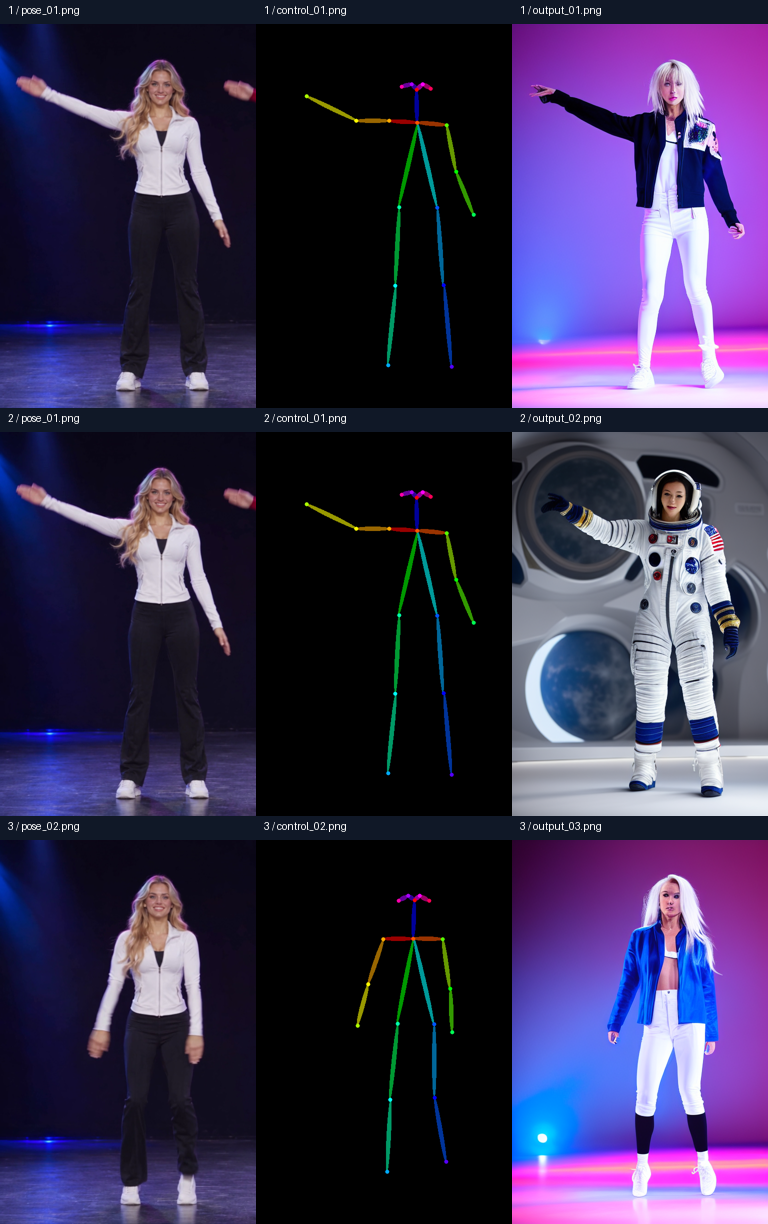

## 10. 추가 영상 데모와 출처

- [41초 음악 포함 최종 영상](dance_final_41s.mp4)
- [41초 LED 관절 영상](samples/led_motion_41s.mp4)
- [영상 프롬프트·동작 시간표](prompts.md)
- 로컬 전체 화면: `start_demo.cmd` 실행(Python 3 필요). 다운로드한 노트를 Colab에서 열면 상대 경로의 MP4는 자동 업로드되지 않습니다. 로컬 데모 화면 또는 폴더의 MP4로 재생하세요.
- 이미지 모델: [SD 1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5), [OpenPose ControlNet](https://huggingface.co/lllyasviel/control_v11p_sd15_openpose)
- 구현 근거: [Diffusers ControlNet 0.35.1](https://huggingface.co/docs/diffusers/v0.35.1/en/api/pipelines/controlnet)
- 영상 도구: [Higgsfield Genjutsu](https://higgsfield.ai/creator-hub/help-center/tools/how-do-i-use-genjutsu)

참조 사진은 이 프로젝트에서 생성한 가상 성인 여성 댄스의 0.5초·8.5초 프레임에서 왼쪽 절반을 자른 것입니다. 첨부 강의 PDF의 사진을 제출 예시로 복제하지 않았습니다. 노래는 사용자 제공 녹화에 포함된 오디오이며 별도 음원 라이선스나 공개 배포 허가를 확보했다는 뜻은 아닙니다.

## 영상 제작 도구 옵션

이미지 과제의 OpenPose/ControlNet 실험은 그대로 유지합니다. 추가 영상 작업은 웹 화면에서 Meta AI/Vibes, Krea, Dola, TikTok Symphony 또는 Higgsfield를 선택할 수 있습니다. 무료 제공 여부와 기능 범위는 `docs/video_tools.md`를 참고하세요.

선택한 서비스에서 생성한 짧은 클립을 내려받은 뒤 로컬 프로그램에서 음악과 함께 41초로 합칩니다. GitHub Pages는 프롬프트 준비와 클립 미리보기를 제공하며, FFmpeg 합성은 `start_demo.cmd`로 연 로컬 서버에서 실행합니다.


## 무엇을 바꿔 보았고, 어떻게 달라졌는가

실행일: 2026-11-12. Colab Tesla T4에서 OpenPose 추출과 SD 1.5 + ControlNet 추론 3건을 실제 실행했습니다. `samples/execution_evidence.json`에 프롬프트·시드·실행 시간·패키지 버전을 기록했습니다.

### 1. 같은 포즈 · 다른 프롬프트 — 실험 01과 02

같은 `pose_01.png`에서 얻은 `control_01.png`와 시드 42를 사용하고, 무대 댄서를 우주비행사로 바꿨습니다. 두 결과 모두 화면 왼쪽 팔을 옆으로 올리고 반대 팔을 내린 큰 자세는 유지했습니다. 배경은 파랑·분홍 무대에서 우주선 내부처럼 보이는 장면으로, 의상은 재킷에서 우주복으로 바뀌었습니다. 다만 팔과 손끝 각도는 완전히 같지 않았습니다. 'lunar base'를 요청했으나 달 표면보다는 창이 있는 실내에 가깝게 나왔습니다.

### 2. 다른 포즈 · 같은 프롬프트 — 실험 01과 03

프롬프트·시드·스텝을 그대로 두고 `pose_01.png`(한 팔 올리기)를 `pose_02.png`(양팔 내리기)로 바꿨습니다. 결과에서도 올렸던 팔이 내려갔습니다. 배경의 파랑·분홍 계열은 비슷하게 남았습니다. 얼굴·재킷 형태·머리 색·바지 배색은 완전히 고정되지 않았습니다. 포즈 조건과 동일 시드만으로 인물 정체성이 유지되는 것은 아니었습니다.

### 3. 잘 따라오지 않은 부분과 한계

- 실험 01·03의 'white sports jacket, black trousers'는 충실히 반영되지 않았습니다. 어두운/파란 재킷과 흰 바지가 나왔습니다.
- 몸 OpenPose만 사용해 손가락·표정·옷 주름은 제어하지 못했습니다. 관절 지도와 결과의 손끝 위치·팔 각도에도 오차가 있습니다.
- 포즈 참조는 생성된 가상 성인 여성 영상에서 왼쪽 인물을 잘라 만든 이미지입니다. 첫 참조 가장자리에는 다른 인물의 손 일부가 남아 있습니다. 관절 지도는 주된 한 인물을 검출했습니다.
- 두 조건쌍을 한 시드에서 비교한 정성 관찰입니다. 포즈와 프롬프트 중 어느 쪽의 영향이 항상 더 크다고 일반화하지 않습니다.

### 추가 41초 영상 데모

직접 작성한 20.5초 LED 관절 시간표를 Higgsfield Genjutsu의 모션 트랜스퍼에 넣고, 금발 성인 여성 두 명의 참조 이미지와 프롬프트로 약 21초 영상을 생성했습니다. 20.5초로 자른 뒤 두 번 연결하고 사용자 녹화의 음악·현장 소리를 합쳐 정확히 41초로 저장했습니다. 최종 영상은 `dance_final_41s.mp4`입니다. 이 영상은 위 SD 1.5 이미지 실험과 별도로 만든 실제 생성 데모입니다. GD의 실제 관절을 추출해 넣은 최종본은 아니며, 음악 박자에 대한 정량 검증도 수행하지 않았습니다.

이 노트는 GitHub에 자동 업로드하지 않습니다. 과제 제출란에 저장소 URL을 등록하는 단계는 별도입니다.